In [4]:
import pandas as pd
import json
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

print("Biblioteker lastet inn!")

W1121 15:25:35.902000 1795 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Biblioteker lastet inn!


In [7]:
with open("../data/diagnoses_clean.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print(f"Lastet {len(df)} diagnoser")
df.head()

Lastet 3103 diagnoser


,id,diagnosis,diagnosis_clean
0,04DD8FF1-66C0-453E-BFCF-A576624862E6,hysteria ?,hysteria ?
1,10478F81-98D2-4F83-8EA6-1EDF1811680C,hysteria 7,hysteria 7
2,97883cca-48aa-46f1-bab0-57f234b2f598,hysteria,hysteria
3,E8F128A2-502F-47E8-B73F-6566E52D4B95,202|hysteria,202|hysteria
4,8F1CC767-D817-4334-B717-D493D2EBC80B,hysteria,hysteria


In [8]:
# Last inn en flerspråklig modell som forstår norsk
model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

# Lag embeddings
embeddings = model.encode(df["diagnosis_clean"].tolist())

print(f"Embeddings laget: {embeddings.shape}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings laget: (3103, 384)


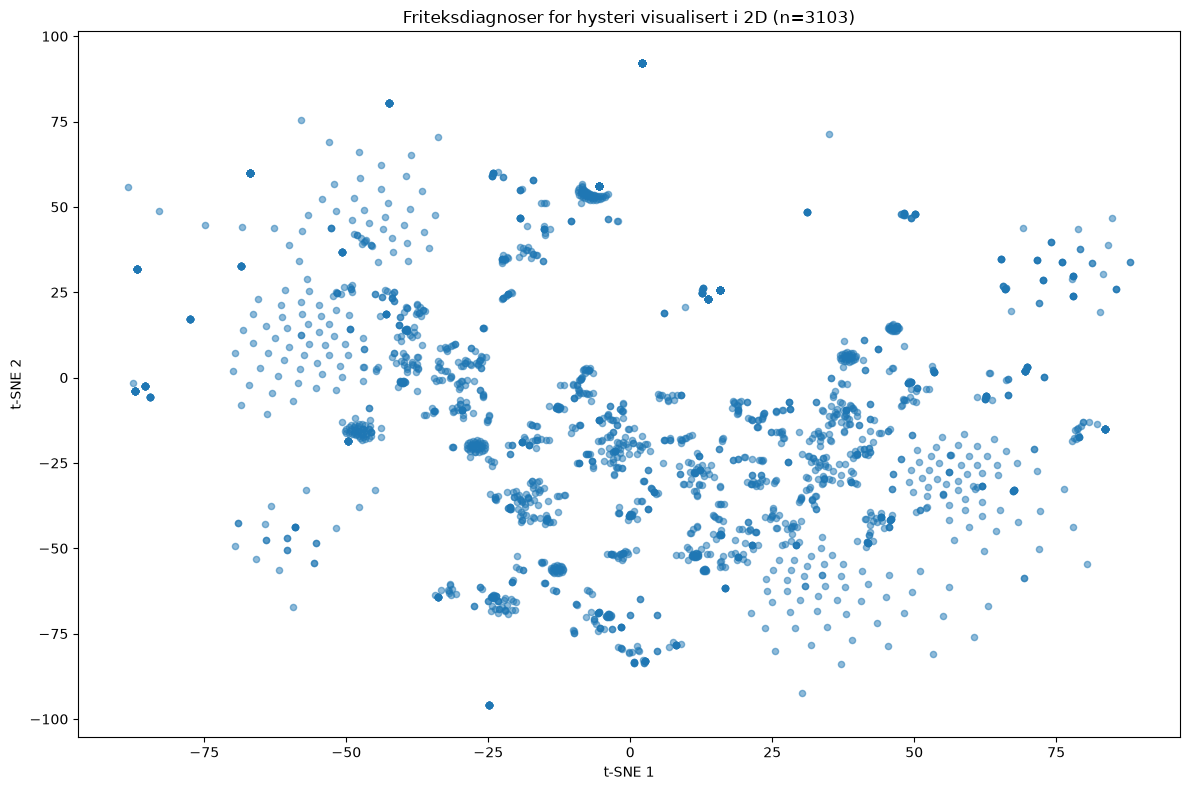

Plot lagret!


In [21]:
# Reduser fra 384 dimensjoner til 2 (for å kunne plotte)
# Med så lite data bruker vi perplexity=2
tsne = TSNE(n_components=2, random_state=42, perplexity=15)
coords = tsne.fit_transform(embeddings)

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(coords[:, 0], coords[:, 1], s=20, alpha=0.5)

ax.set_title("Friteksdiagnoser for hysteri visualisert i 2D (n=3103)")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
plt.tight_layout()
plt.savefig("../results/diagnose_kart.png", dpi=150)
plt.show()

print("Plot lagret!")

In [10]:
# Finn de mest isolerte punktene
# (de med størst avstand fra sentrum)
avstand = np.sqrt(coords[:, 0]**2 + coords[:, 1]**2)
df["avstand"] = avstand
df.nlargest(10, "avstand")[["id", "diagnosis"]]

,id,diagnosis
2652,4d69bc06-cda1-4c6d-84bf-685e08d7ba2f,ins ex const
2127,027fce80-831c-4138-a7ce-dc93e93f8825,hysteriform
2132,103de465-c90e-4276-8b1a-9e7e9c55697f,hysteriform
2312,4da94ff5-2a6f-4a70-a1de-c51d5b944a59,hysteriform
2316,60898974-d883-4c2f-8155-0e5433225135,hysteriform
2328,51f4379d-9955-4d73-8507-1ddbc1d83977,hysteriform
2448,d123c568-f883-4d44-bbeb-304725e857ed,hysteriform
2477,244b42f0-7356-40ba-b89d-b65772abc63a,hysteriform
2518,332a44b0-5b84-42b4-8c41-cf7b7e5a49fc,hysteriform
2579,532c9d89-b28c-450e-87cb-3755455adc18,hysteriform


In [11]:
from sklearn.neighbors import NearestNeighbors

# Finn avstand til nærmeste nabo for hvert punkt
nn = NearestNeighbors(n_neighbors=2)
nn.fit(coords)
avstander, _ = nn.kneighbors(coords)

# Nærmeste nabo er indeks 1 (indeks 0 er punktet selv)
df["nabo_avstand"] = avstander[:, 1]

pd.set_option("display.max_colwidth", None)

# Vis de 15 mest isolerte
topp_isolerte = df.nlargest(15, "nabo_avstand")[["id", "diagnosis", "nabo_avstand"]]
print("De 15 mest isolerte diagnosene:")
topp_isolerte

De 15 mest isolerte diagnosene:


,id,diagnosis,nabo_avstand
245,FEB4C535-615F-4318-9D0C-4F5F8F836B5E,insania ex-constitutione,23.347362
1583,b4eefdcc-3a21-4997-92d8-76b606469bb0,psychosis ex constitutione manico melancholica hysteriform,11.043259
2126,0b0c2883-4938-4eba-9ff8-c63636a9a3de,hysteriform,10.835896
1010,c048f872-f330-459b-ba8d-bc9d241d79d9,insan hysteria,9.473147
2648,4c75296e-abe2-4264-8d16-b863f084b538,ins ex const,8.839712
2652,4d69bc06-cda1-4c6d-84bf-685e08d7ba2f,ins ex const,8.839712
2359,35e0d32d-3ec2-4247-9c6a-99f4ef9121ea,hysterisk nevrose,8.686697
2215,a5e11215-9a35-43f4-87ed-693b0b16c034,hysteriform,8.406574
2640,5bc8a5e9-1302-408f-822c-aee00587440c,ins ex const,8.311154
2134,1011ee4f-7619-485b-b59a-3d5146245619,hysteriform,8.174635


In [13]:
# Lagre embeddings som numpy-fil
np.save("../data/embeddings.npy", embeddings)
print("Embeddings lagret!")

Embeddings lagret!


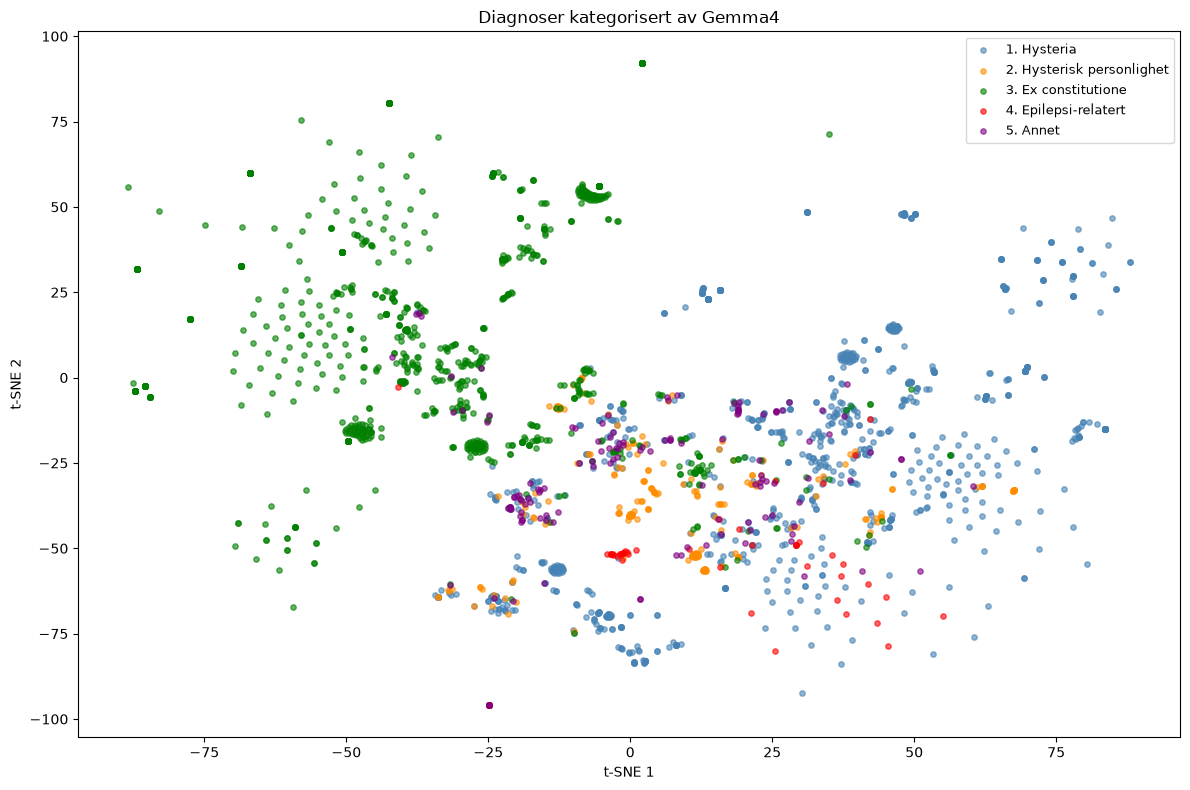

In [22]:
# Last inn klassifiserte data og lage plot

df_klassifisert = pd.read_json("../data/klassifisert.json")

# Farger per kategori
farger = {
    "1. Hysteria": "steelblue",
    "2. Hysterisk personlighet": "darkorange",
    "3. Ex constitutione": "green",
    "4. Epilepsi-relatert": "red",
    "5. Annet": "purple"
}

fig, ax = plt.subplots(figsize=(12, 8))

for kategori, farge in farger.items():
    maske = df_klassifisert["kategori"] == kategori
    ax.scatter(coords[maske, 0], coords[maske, 1],
               c=farge, label=kategori, s=15, alpha=0.6)

ax.set_title("Diagnoser kategorisert av Gemma4")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig("../results/diagnose_kart_farger.png", dpi=150)
plt.show()